In [1]:
import math
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import display
from PIL import Image

CUBE_DIR = Path('./outputs/studio_small_09_cube')
ERP_HEIGHT = 512
OUTPUT_PATH = Path('./outputs/studio_small_09_erp_from_cube.png')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

FACE_FILES = ('posx.png', 'negx.png', 'posy.png', 'negy.png', 'posz.png', 'negz.png')

In [2]:
def cubemap_to_erp(cubemap, height):
    """Project [B, 6, C, S, S] cube faces to an ERP of shape [B, C, H, 2H]."""
    if cubemap.ndim != 5:
        raise ValueError('Expected cubemap shape [B, 6, C, S, S]')
    batch, face_count, channels, face_height, face_width = cubemap.shape
    if face_count != 6 or face_height != face_width or min(batch, channels, face_height) < 1:
        raise ValueError(f'Expected six nonempty square faces, got {tuple(cubemap.shape)}')
    if cubemap.dtype not in (torch.float32, torch.float64):
        raise TypeError('Use float32 or float64 for cubemap values')
    if not isinstance(height, int) or height < 1:
        raise ValueError('ERP height must be a positive integer')

    width = 2 * height
    options = {'device': cubemap.device, 'dtype': cubemap.dtype}
    longitude = ((torch.arange(width, **options) + 0.5) / width - 0.5) * (2 * math.pi)
    latitude = (0.5 - (torch.arange(height, **options) + 0.5) / height) * math.pi
    phi, theta = torch.meshgrid(latitude, longitude, indexing='ij')
    cos_phi = phi.cos()
    x = cos_phi * theta.sin()
    y = phi.sin()
    z = cos_phi * theta.cos()
    directions = torch.stack((x, y, z), dim=-1)

    # The dominant axis and its sign select a face in +X, -X, +Y, -Y, +Z, -Z order.
    axis = directions.abs().argmax(dim=-1, keepdim=True)
    dominant = directions.gather(-1, axis).squeeze(-1)
    face_indices = 2 * axis.squeeze(-1) + (dominant < 0).long()
    # These are the right and down components used by make_face_directions.
    face_coordinates = ((-z, -y), (z, -y), (x, z), (x, -z), (x, -y), (-x, -y))

    erp = cubemap.new_empty(batch, channels, height, width)
    for index, (u, v) in enumerate(face_coordinates):
        mask = face_indices == index
        coordinates = torch.stack((u[mask], v[mask]), dim=-1)
        if coordinates.numel() == 0:
            continue
        coordinates = coordinates / dominant[mask].abs().unsqueeze(-1)
        grid = coordinates.reshape(1, 1, -1, 2).expand(batch, -1, -1, -1)
        sampled = F.grid_sample(
            cubemap[:, index], grid,
            mode='bilinear', padding_mode='border', align_corners=False,
        )
        erp[:, :, mask] = sampled.squeeze(2)

    return erp

In [3]:
face_pixels = []
expected_size = None
for filename in FACE_FILES:
    path = CUBE_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f'Missing cubemap face: {path.resolve()}')
    with Image.open(path) as face_image:
        if expected_size is None:
            expected_size = face_image.size
        if face_image.width != face_image.height or face_image.size != expected_size:
            raise ValueError(f'All faces must have the same square size. {path} is {face_image.size}')
        face_pixels.append(np.asarray(face_image.convert('RGB')))

cubemap = torch.from_numpy(np.stack(face_pixels)).permute(0, 3, 1, 2).unsqueeze(0)
cubemap = cubemap.to(device=DEVICE, dtype=torch.float32) / 255
print('Cubemap:', tuple(cubemap.shape), 'device:', cubemap.device)

Cubemap: (1, 6, 3, 512, 512) device: cuda:0


ERP: (1024, 512) device: cuda:0
Saved: E:\model\erpProcess\outputs\studio_small_09_erp_from_cube.png


**原始 ERP**

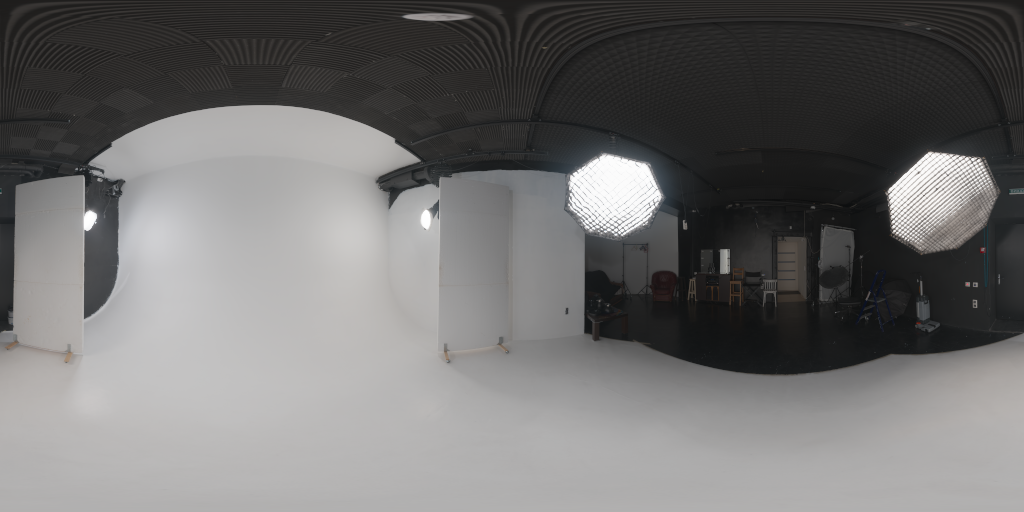

**重建 ERP**

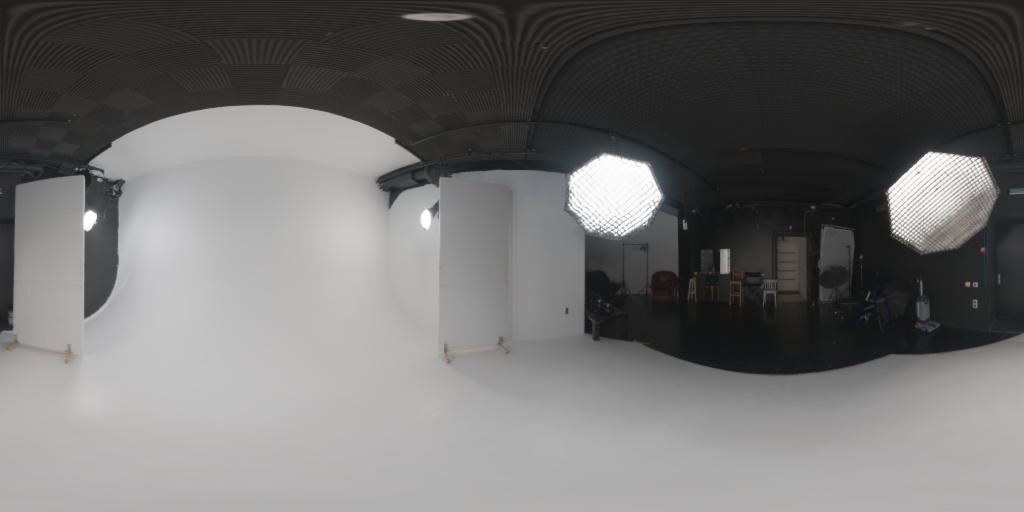

In [4]:
from IPython.display import Markdown

erp = cubemap_to_erp(cubemap, ERP_HEIGHT)
pixels = erp[0].permute(1, 2, 0).clamp(0, 1).mul(255).round().to(torch.uint8).cpu().numpy()
erp_image = Image.fromarray(pixels)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
erp_image.save(OUTPUT_PATH)
print('ERP:', erp_image.size, 'device:', erp.device)
print('Saved:', OUTPUT_PATH.resolve())

original_erp_path = CUBE_DIR / 'erp_preview.png'
if original_erp_path.is_file():
    with Image.open(original_erp_path) as original_image:
        original_erp = original_image.convert('RGB').resize(erp_image.size, Image.Resampling.LANCZOS)
    display(Markdown('**原始 ERP**'), original_erp)
else:
    print(f'Original ERP preview not found: {original_erp_path.resolve()}')
display(Markdown('**重建 ERP**'), erp_image)